# Atlas-DeePC: Linear-Subspace Rank, λg = 0, OSQP

**Every integer rank from 20 through 80, each on the same 100 seeds (211–310):
6,100 full-duration rollouts. Rank 60 is the baseline at sweep launch.** These seeds have
been used for exploratory ablations; this is not an untouched test set.

Only `svd_rank` changes. The controller is the frozen launch version of
`baseline_atlas_deepc.BaselineAtlasDeePC`:
48 frozen physical-configuration charts, **uncentered linear** behavioral bases,
current-chart DeePC, graph waypoint references, and iterative N=10 terminal
configuration selection. The archived contextual affine-rank study is a separate
experiment; none of its results are used here.

This fresh sweep uses **$\lambda_g=0$ and OSQP**. Within this sweep only
rank varies. The previous complete study used $\lambda_g=0.05$ and Clarabel,
so the comparison below changes **both regularization and solver** and cannot
attribute differences to either alone. The interrupted $\lambda_g=0$ Clarabel
sweep remains separate; its partial checkpoints are not used as OSQP results.

OSQP 1.0.4 through CVXPY 1.6.5 uses `max_iter=10000`, `eps_abs=1e-5`,
`eps_rel=1e-5`, and polishing enabled (the installed CVXPY defaults made explicit).
Other OSQP settings use package defaults. There is no fallback solver. Frozen
sources and hashes record the solver selection and options for every rollout.
All controller weights other than the requested coefficient penalty, chart geometry,
goal policy, offline data and evaluation seeds match the completed study.

## Fixed setup

- Same random-exploration offline data, seeds 2026–2225; no new trajectories.
- Full input–output Hankel columns, $H\in\mathbb R^{144\times37800}$, ten outputs,
  two inputs, past horizon 2 and prediction horizon 10.
- Frozen chart memberships, centers, graph, and representatives. Localization
  uses the latest past configuration; input-feature weight is zero.
- Rank-$r$ basis is computed from the **uncentered** chart matrix via the existing
  eigendecomposition of $XX^\top$. Offset is zero; no $\sum g=1$ constraint.
- Coefficient bounds are the projected offline coordinate mean ±3 standard
  deviations (with the baseline $10^{-8}$ scale floor), recomputed at each rank.
- $Q=\mathrm{diag}(5000,5000,5000,5000,20,20,10^5,10^5,5000,5000)$,
  $R=10^{-4}I$, $\lambda_g=0$, $\lambda_{ini}=10^5$, $\lambda_{\Delta u}=5$;
  no additional terminal cost, input limits $[-1,1]$, 320 steps.
- Same ten nearest eligible offline terminal candidates, at least 6 cm source
  target separation; candidate choice minimizes directed route cost online.
  Exact target position, zero reference velocities, and the 7 cm latch are retained.
- No measurement noise, contextual rescue, fitted model, IK, or trajectory replay.

**QP failure behavior:** the unchanged baseline runner applies a zero input when
the QP returns no solution, then continues the rollout. Those steps are retained
and counted as unsolved; they are not QP-generated actions. This matters at low
ranks. `optimal_inaccurate` is accepted by the existing baseline and is excluded
from the unsolved count. Compact checkpoints retain aggregate counts by solver
status in their summary, while individual per-step status arrays are discarded.
Status counts alone do not identify the underlying numerical failure mechanism.

Changing rank changes the number of behavioral coefficients and the retained
subspace; it does not refit clustering or retune any control weights. Nominal rank
means the number of retained basis columns, not a thresholded numerical-rank estimate.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap
from IPython.display import HTML, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/linear_subspace_rank_ablation.py").exists())
FROZEN_SOURCE = ROOT / "experiments/routed_deepc_iid/linear_subspace_rank_lamg0_osqp_100_v1/frozen_protocol/src"
assert FROZEN_SOURCE.is_dir(), "The verified launch-source snapshot is required."
sys.path.insert(0, str(FROZEN_SOURCE))
import linear_subspace_rank_ablation as experiment
assert Path(experiment.__file__).resolve().parent == FROZEN_SOURCE.resolve()
get_ipython().run_line_magic("matplotlib", "inline")
RUN_EXPERIMENTS = False
WORKERS = 6
RANKS = list(range(20, 81))
SEEDS = list(range(211, 311))
BASELINE_RANK = 60
if RUN_EXPERIMENTS:
    experiment.run_all(RANKS, SEEDS, workers=WORKERS)
RESULT_ROOT = experiment.RESULT_ROOT
payload = json.loads((RESULT_ROOT / "summary.json").read_text())
assert payload["version"] == experiment.VERSION
assert payload["ranks"] == RANKS and payload["seeds"] == SEEDS
assert payload["complete"], "Sweep is still in progress; do not report partial results as complete."
assert [row["rank"] for row in payload["completed"]] == RANKS
assert experiment.prepare() == payload["signature"], "Experiment sources/data changed."
assert payload["signature"]["base_config"]["lam_g"] == 0.0
assert payload["signature"]["qp_solver"] == "OSQP"
panels, records = {}, []
for rank in RANKS:
    panel = json.loads((RESULT_ROOT / f"rank{rank:03d}" / "summary.json").read_text())
    assert panel["version"] == experiment.VERSION and panel["rank"] == rank
    assert panel["seeds"] == SEEDS and [r["seed"] for r in panel["results"]] == SEEDS
    assert panel["timing"]["timed_steps"] == 31500
    panels[rank] = panel
    for summary_row in panel["results"]:
        seed = summary_row["seed"]
        row = experiment.load_checkpoint(experiment.checkpoint_path(rank, seed), rank, seed)
        assert row == summary_row
        records.append({**row, "rank": rank, "strict": experiment.strict_success(row),
                        "tail100_mm": 1000*row["mean_last_100"]})
frame = pd.DataFrame(records)
assert len(frame) == 6100 and not frame.duplicated(["rank", "seed"]).any()
for seed in SEEDS:
    targets = np.array(frame.loc[frame.seed == seed, "exact_target_xy"].tolist())
    np.testing.assert_array_equal(targets, np.repeat(targets[:1], len(RANKS), axis=0))
audit = json.loads((RESULT_ROOT / "fairness_audit.json").read_text())
print("Verified: 61 ranks × 100 paired seeds = 6,100 rollouts; 320 steps each.")
print("All checkpoint metrics, identical targets, linear baseline parameters, source hashes, and timing counts verified.")
display(pd.Series({"Offline seed range": audit["data_seed_range"],
    "Stabilized offline episodes": audit["offline_stabilized_episode_count"],
    "Timed steps per rank": 31500,
    "Baseline rank": BASELINE_RANK}))
BLUE, ORANGE, GRAY = "#0072B2", "#D55E00", "#667085"
def rank_axis(ax, ylabel):
    ax.axvline(BASELINE_RANK, color=GRAY, linestyle="--", linewidth=1, label="Rank 60 baseline")
    ax.set(xlim=(20, 80), xlabel="Retained linear-subspace rank", ylabel=ylabel)
    ax.grid(alpha=.2)
def save_show(fig, name):
    fig.savefig(RESULT_ROOT / name, dpi=160)
    plt.show()


Verified: 61 ranks × 100 paired seeds = 6,100 rollouts; 320 steps each.
All checkpoint metrics, identical targets, linear baseline parameters, source hashes, and timing counts verified.


Offline seed range             [2026, 2225]
Stabilized offline episodes               0
Timed steps per rank                  31500
Baseline rank                            60
dtype: object

## Success and final-window error

Strict success requires **both** the final-30 and final-100 windows to have mean
fingertip error <10 mm and maximum error <20 mm. All 320 steps are evaluated;
entering the 10 mm neighborhood once is reported separately. The 10 mm line in
mean-error plots represents only one part of this success definition.


,successes,median_tail100_mm,p90_tail100_mm,ever_reached_10mm,unsolved_qps,rollouts_with_unsolved_qps
rank,,,,,,
20,0,73.839,148.396,80,14229,100
40,80,5.594,14.391,91,0,0
60,93,2.062,5.415,94,0,0
80,83,2.336,19.107,86,115,12


Rank 60: 93/100 strict successes.
Highest observed success: 97/100, ranks [59, 62]. Exploratory comparison; no held-out selection claim.


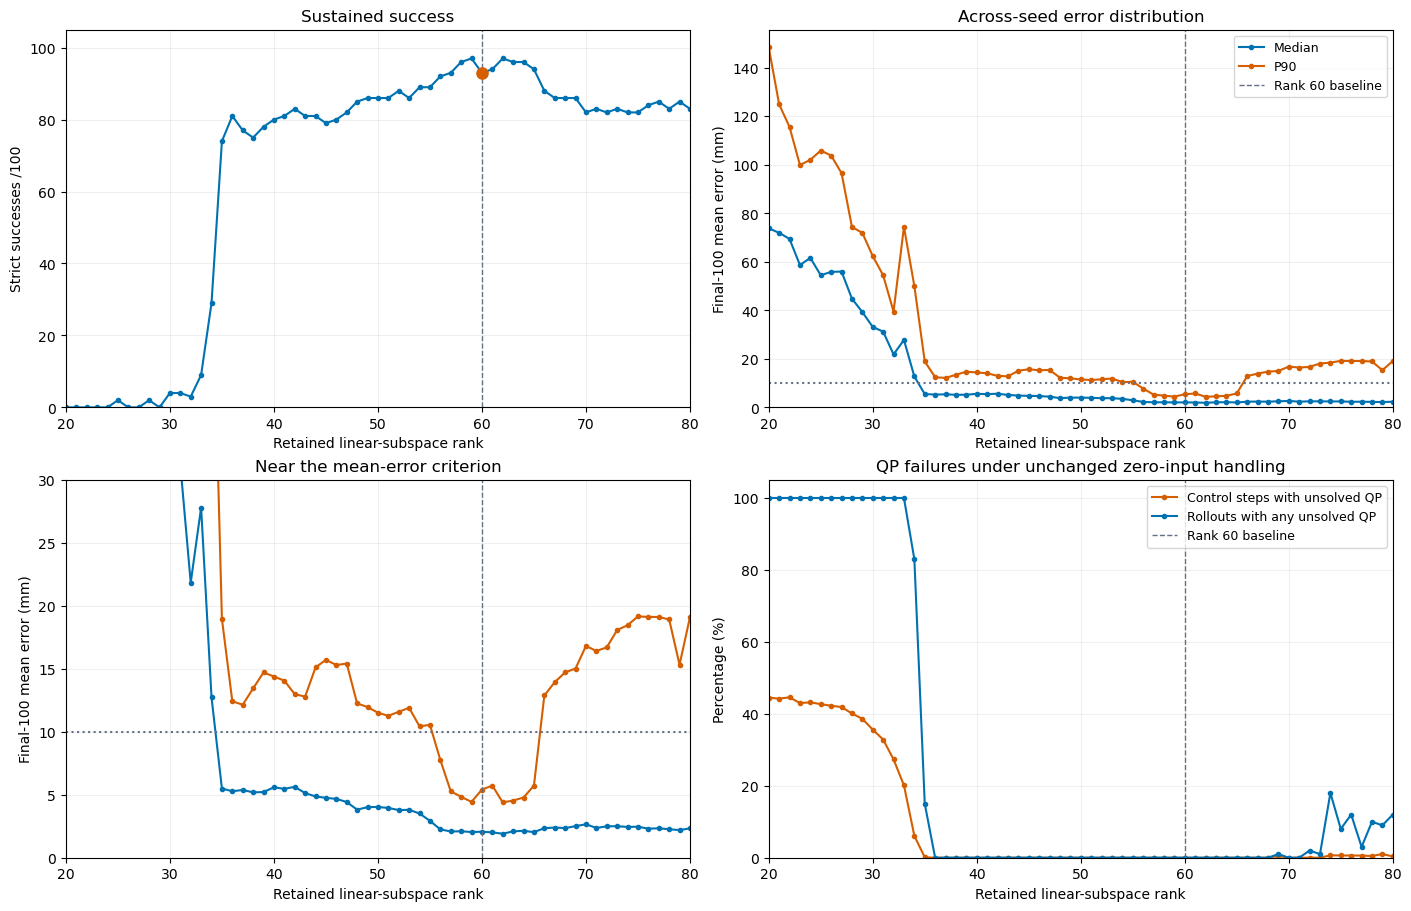

,successes,median_tail100_mm,p90_tail100_mm,ever_reached_10mm,unsolved_qps,rollouts_with_unsolved_qps
rank,,,,,,
20,0,73.839,148.396,80,14229,100
21,0,71.963,124.948,79,14155,100
22,0,69.445,115.603,79,14266,100
23,0,58.682,99.902,86,13756,100
24,0,61.629,102.057,86,13822,100
25,2,54.481,105.880,87,13663,100
26,0,55.867,103.832,90,13517,100
27,0,55.991,96.587,88,13403,100
28,2,44.828,74.413,92,12833,100


In [2]:
summary = pd.DataFrame([{"rank": rank,
    "successes": panels[rank]["successes"],
    "median_tail100_mm": panels[rank]["median_tail100_mm"],
    "p90_tail100_mm": panels[rank]["p90_tail100_mm"],
    "ever_reached_10mm": int(frame.loc[frame["rank"] == rank, "ever_reached_10mm"].sum()),
    "unsolved_qps": panels[rank]["unsolved_qps"],
    "rollouts_with_unsolved_qps": int((frame.loc[frame["rank"] == rank, "unsolved_steps"] > 0).sum())
    } for rank in RANKS]).set_index("rank")
display(summary.loc[[20, 40, 60, 80]].round(3))
best_count = int(summary.successes.max())
best_ranks = summary.index[summary.successes == best_count].tolist()
print(f"Rank 60: {summary.loc[60, 'successes']:.0f}/100 strict successes.")
print(f"Highest observed success: {best_count}/100, ranks {best_ranks}. Exploratory comparison; no held-out selection claim.")
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
axes = axes.ravel()
axes[0].plot(RANKS, summary.successes, color=BLUE, marker=".")
axes[0].scatter([60], [summary.loc[60, "successes"]], color=ORANGE, s=65, zorder=5)
rank_axis(axes[0], "Strict successes /100")
axes[0].set_ylim(0, 105)
axes[0].set_title("Sustained success")
for ax in axes[1:3]:
    ax.plot(RANKS, summary.median_tail100_mm, color=BLUE, marker=".", label="Median")
    ax.plot(RANKS, summary.p90_tail100_mm, color=ORANGE, marker=".", label="P90")
    ax.axhline(10, color=GRAY, linestyle=":")
    rank_axis(ax, "Final-100 mean error (mm)")
    ax.set_ylim(bottom=0)
axes[1].set_title("Across-seed error distribution")
axes[1].legend(fontsize=9)
axes[2].set(title="Near the mean-error criterion", ylim=(0, 30))
axes[3].plot(RANKS, 100*summary.unsolved_qps/32000, color=ORANGE, marker=".", label="Control steps with unsolved QP")
axes[3].plot(RANKS, summary.rollouts_with_unsolved_qps, color=BLUE, marker=".", label="Rollouts with any unsolved QP")
rank_axis(axes[3], "Percentage (%)")
axes[3].set(title="QP failures under unchanged zero-input handling", ylim=(0, 105))
axes[3].legend(fontsize=9)
save_show(fig, "rank_success_errors.png")
display(HTML("<details><summary>All 61 rank summaries</summary>" + summary.round(3).to_html() + "</details>"))


## All paired seeds

The left panel shows final-100 mean error, with logarithmic color scaling to
retain detail near 10 mm across the full error range. The right panel shows the
complete strict-success test. Each row contains the same 100 seeds. The dashed
horizontal line marks rank 60; no seed is dropped because of failure.


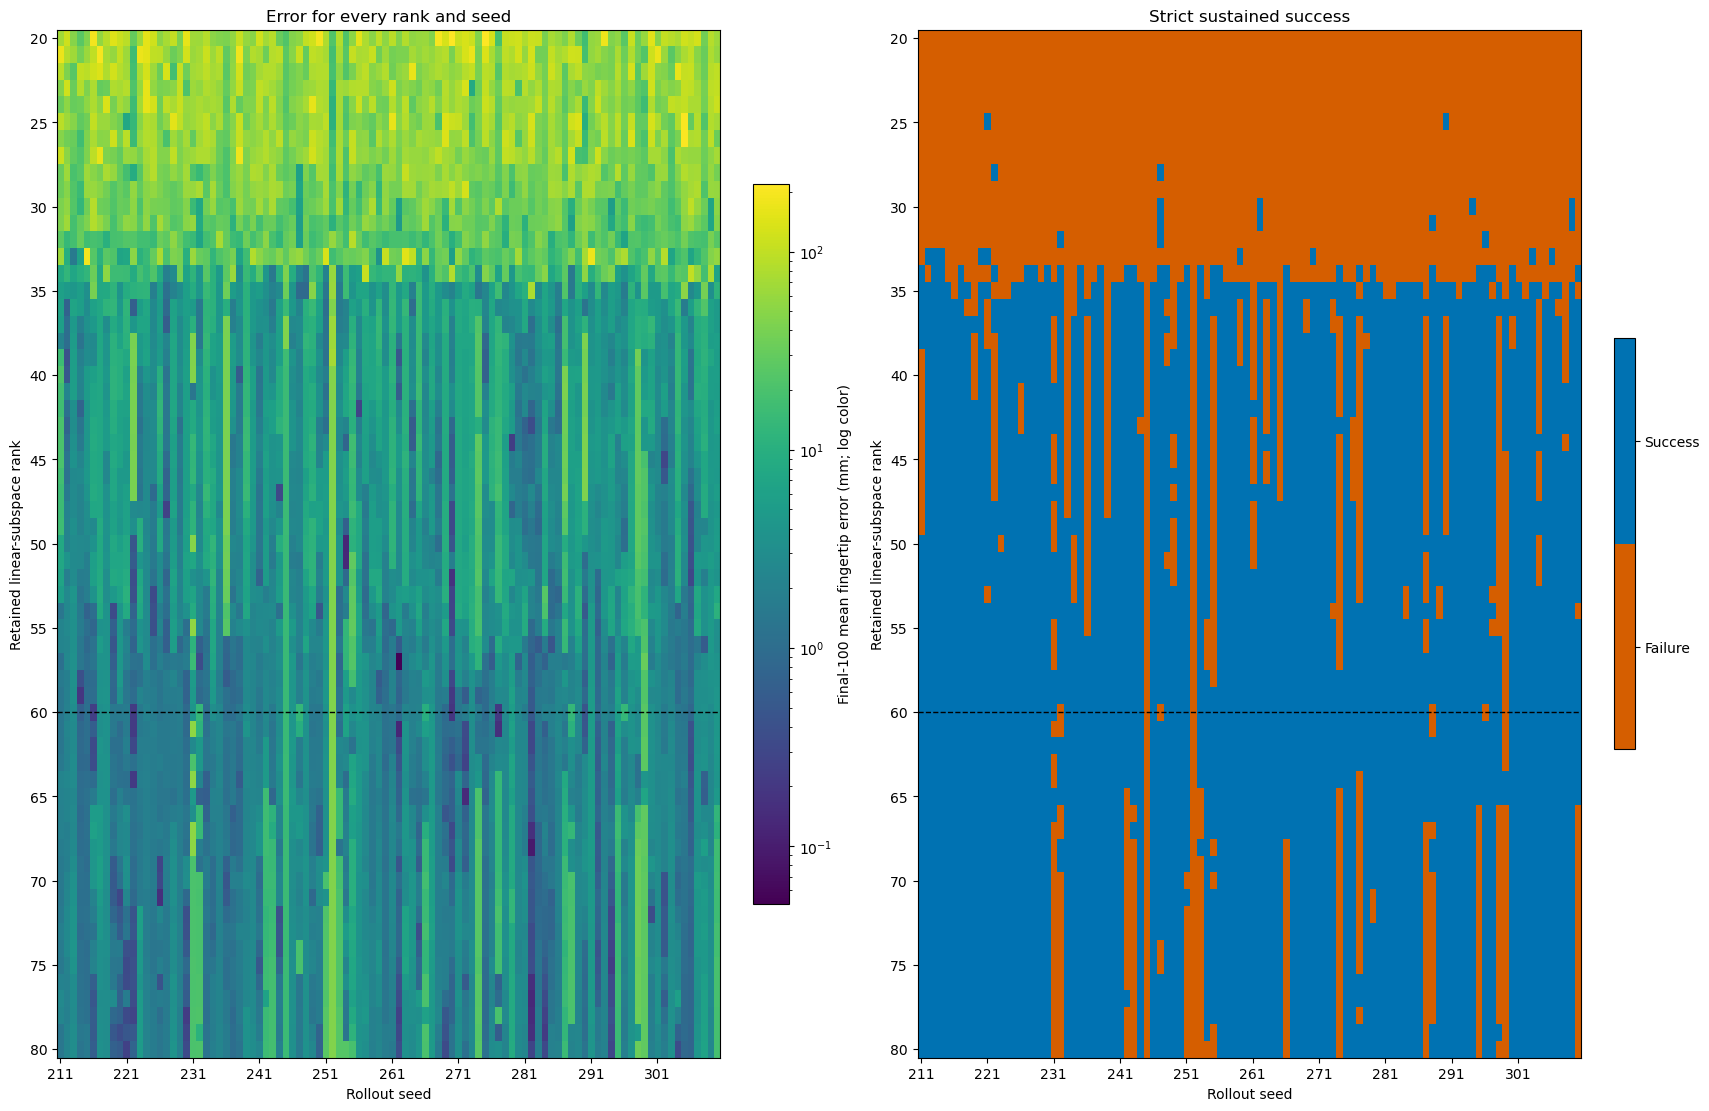

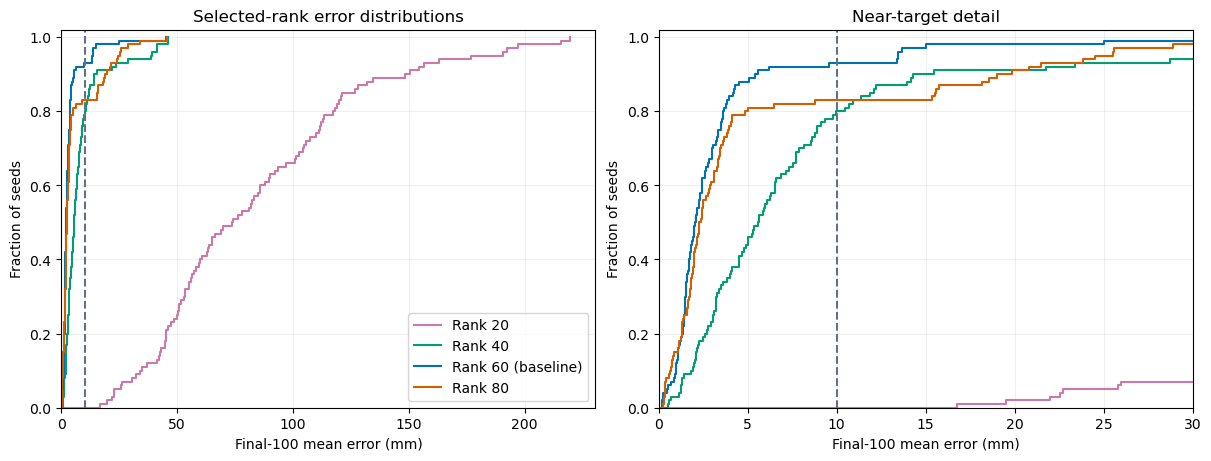

In [3]:
error_grid = frame.pivot(index="rank", columns="seed", values="tail100_mm").loc[RANKS, SEEDS]
success_grid = frame.pivot(index="rank", columns="seed", values="strict").loc[RANKS, SEEDS]
fig, axes = plt.subplots(1, 2, figsize=(17, 11), constrained_layout=True)
extent = (210.5, 310.5, 80.5, 19.5)
minimum = max(float(error_grid.min().min()), .001)
im = axes[0].imshow(error_grid, aspect="auto", interpolation="nearest", extent=extent,
    norm=LogNorm(vmin=minimum, vmax=max(10, float(error_grid.max().max()))), cmap="viridis")
fig.colorbar(im, ax=axes[0], label="Final-100 mean fingertip error (mm; log color)", shrink=.7)
im2 = axes[1].imshow(success_grid.astype(int), aspect="auto", interpolation="nearest", extent=extent,
    cmap=ListedColormap(["#D55E00", "#0072B2"]), vmin=-.5, vmax=1.5)
bar = fig.colorbar(im2, ax=axes[1], ticks=[0, 1], shrink=.4)
bar.ax.set_yticklabels(["Failure", "Success"])
for ax, title in zip(axes, ["Error for every rank and seed", "Strict sustained success"]):
    ax.axhline(60, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="Rollout seed", ylabel="Retained linear-subspace rank", title=title,
           xticks=list(range(211, 311, 10)), yticks=list(range(20, 81, 5)))
save_show(fig, "rank_seed_heatmaps.png")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for rank, color in zip([20, 40, 60, 80], ["#CC79A7", "#009E73", BLUE, ORANGE]):
    values = np.sort(error_grid.loc[rank].to_numpy())
    for ax in axes:
        ax.step(np.r_[0, values], np.r_[0, np.arange(1, 101)/100], where="post",
                label=f"Rank {rank}" + (" (baseline)" if rank == 60 else ""), color=color)
for ax, title in zip(axes, ["Selected-rank error distributions", "Near-target detail"]):
    ax.set(xlim=(0, None), ylim=(0, 1.02), xlabel="Final-100 mean error (mm)", ylabel="Fraction of seeds", title=title)
    ax.axvline(10, color=GRAY, linestyle="--")
    ax.grid(alpha=.2)
axes[1].set_xlim(0, 30)
axes[0].legend()
save_show(fig, "rank_error_distributions.png")


## Repaired and regressed seeds relative to rank 60

A repaired seed fails at rank 60 and succeeds at the comparison rank. A regressed
seed succeeds at rank 60 and fails at the comparison rank. These are paired
outcomes, not independent evaluation samples at each rank.


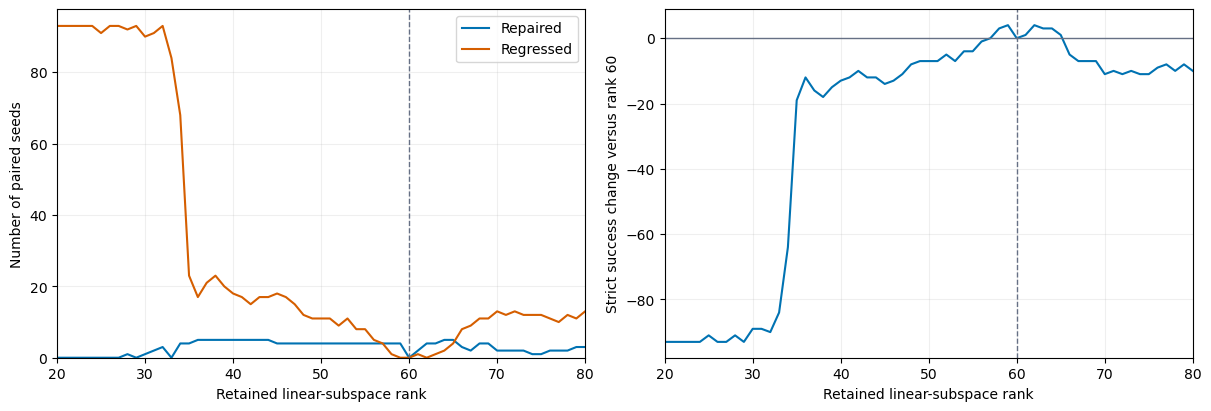

,repaired_count,regressed_count,net_success_change,repaired_seeds,regressed_seeds
rank,,,,,
20,0,93,-93,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
21,0,93,-93,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
22,0,93,-93,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
23,0,93,-93,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
24,0,93,-93,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
25,0,91,-91,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
26,0,93,-93,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
27,0,93,-93,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
28,1,92,-91,[247],"[211, 212, 213, 214, 215, 216, 217,

rank,seed,strict,tail100_mm,unsolved_steps
20,211,False,68.919,143
20,212,False,117.116,136
20,213,False,48.534,143
20,214,False,25.958,129
20,215,False,44.777,154
20,216,False,192.557,143
20,217,False,57.321,139
20,218,False,89.585,149
20,219,False,148.185,150
20,220,False,111.767,139


In [4]:
base = success_grid.loc[60].to_numpy(dtype=bool)
paired_records = []
for rank in RANKS:
    current = success_grid.loc[rank].to_numpy(dtype=bool)
    repaired = np.asarray(SEEDS)[current & ~base].tolist()
    regressed = np.asarray(SEEDS)[~current & base].tolist()
    paired_records.append({"rank": rank, "repaired_count": len(repaired), "regressed_count": len(regressed),
        "net_success_change": len(repaired)-len(regressed), "repaired_seeds": repaired, "regressed_seeds": regressed})
paired = pd.DataFrame(paired_records).set_index("rank")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(RANKS, paired.repaired_count, color=BLUE, label="Repaired")
axes[0].plot(RANKS, paired.regressed_count, color=ORANGE, label="Regressed")
axes[0].set_ylim(bottom=0)
axes[0].legend()
rank_axis(axes[0], "Number of paired seeds")
axes[1].plot(RANKS, paired.net_success_change, color=BLUE)
axes[1].axhline(0, color=GRAY, linewidth=1)
rank_axis(axes[1], "Strict success change versus rank 60")
save_show(fig, "rank_paired_changes.png")
display(HTML("<details><summary>Repaired and regressed seed lists for every rank</summary>" + paired.to_html() + "</details>"))
display(HTML("<details><summary>All 6,100 per-seed results</summary>" + frame[["rank", "seed", "strict", "tail100_mm", "unsolved_steps"]].round(3).to_html(index=False) + "</details>"))


## Computation time

Six workers, one numerical-library thread per worker, on a shared computer.
Rank 60 runs first, followed by the other ranks in ascending order. Rank and run
order are therefore confounded with changes in system load: these measurements
are descriptive, not an isolated hardware benchmark.

Timings discard the first five steps of every rollout, leaving **31,500 timed
steps per rank**. QP time includes construction and solve. Offline SVD and
simulator stepping are excluded. One-time candidate setup is reported separately.
Module means add to mean total time; medians and P99 values generally do not add.
All computation-time axes are linear and start at zero.


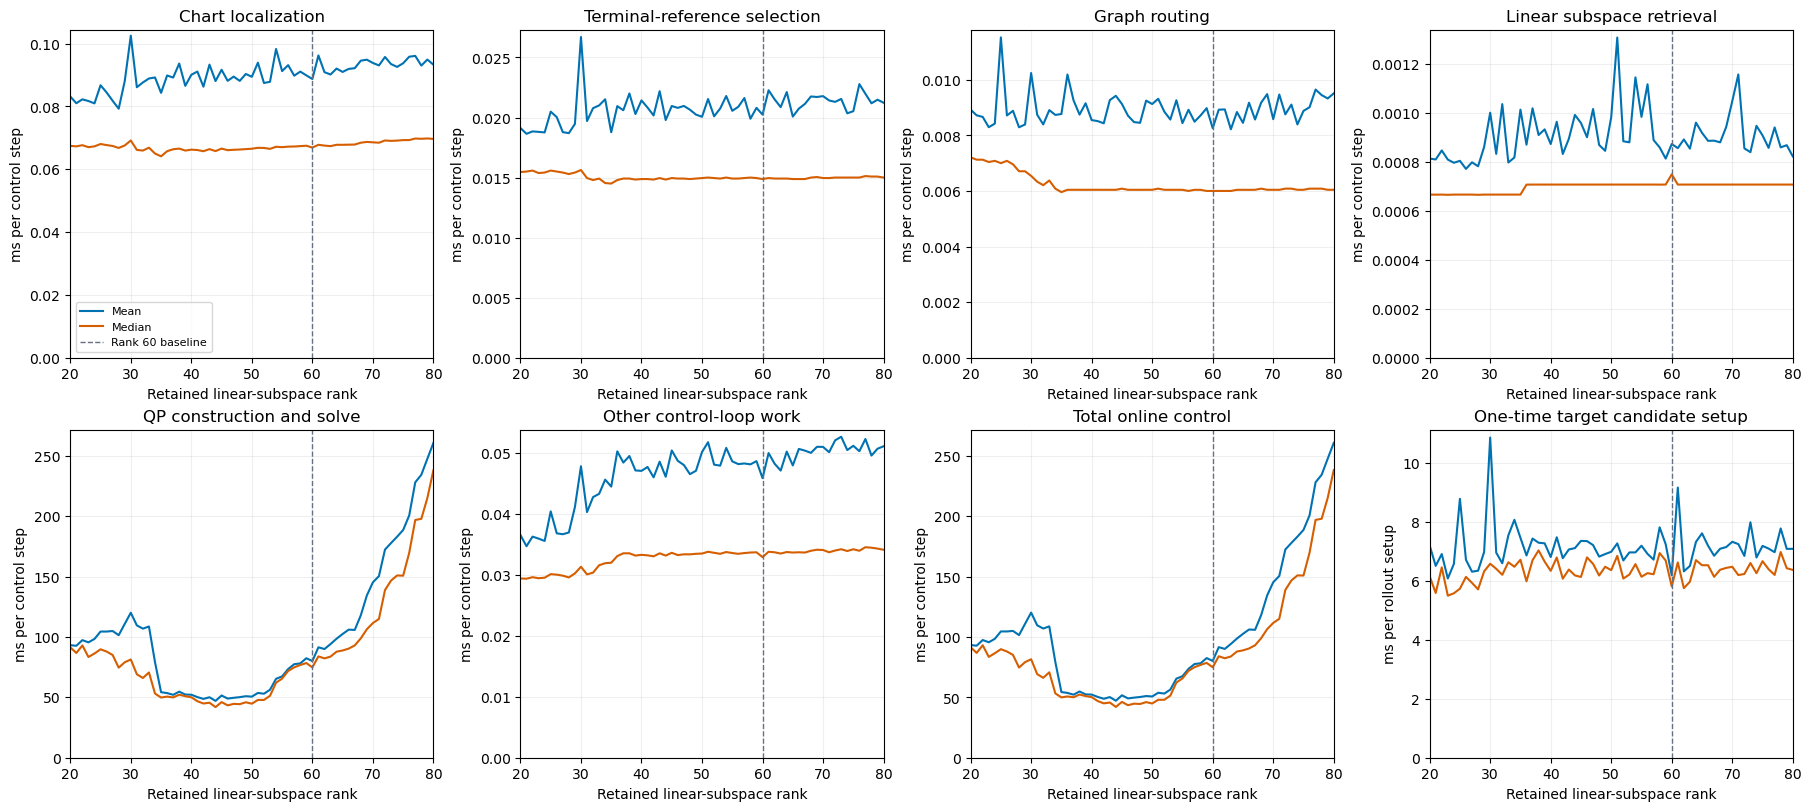

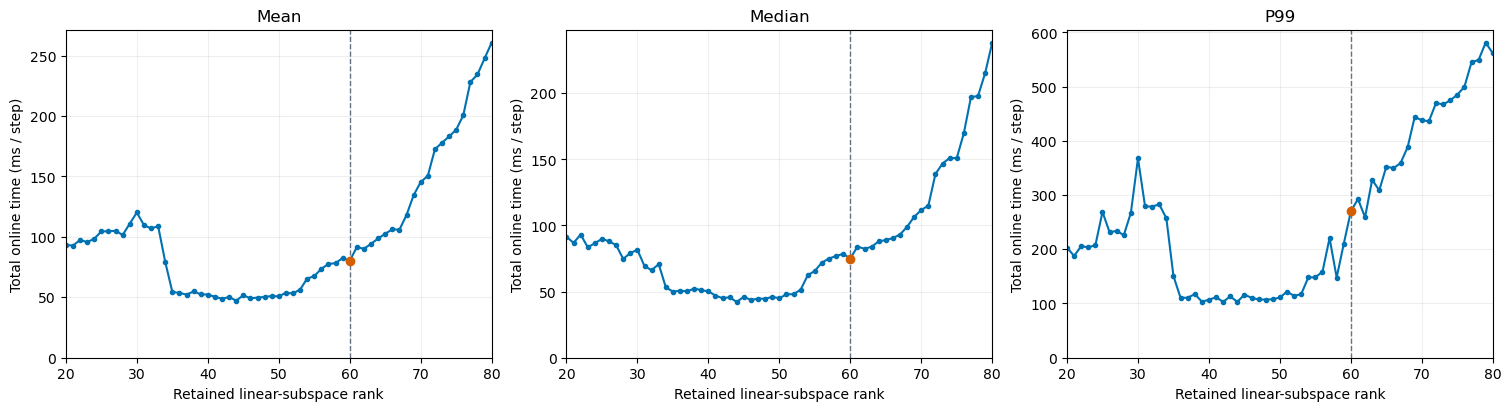

,mean_ms,median_ms,p99_ms
rank,,,
20,93.315,91.499,203.201
40,52.304,50.211,106.689
60,80.186,74.919,269.978
80,260.812,238.240,561.451


rank,module,mean_ms,median_ms,p95_ms,p99_ms,share_of_mean_total
20,Chart localization,0.0832,0.0675,0.1490,0.3421,0.0009
20,Terminal-reference selection,0.0191,0.0155,0.0264,0.0648,0.0002
20,Graph routing,0.0089,0.0072,0.0133,0.0330,0.0001
20,Linear subspace retrieval,0.0008,0.0007,0.0011,0.0019,0.0000
20,QP construction and solve,93.1666,91.3479,162.2865,202.4037,0.9984
20,Other control-loop work,0.0365,0.0294,0.0582,0.1327,0.0004
20,Total online control,93.3151,91.4988,162.4604,203.2007,1.0000
21,Chart localization,0.0810,0.0673,0.1433,0.3138,0.0009
21,Terminal-reference selection,0.0186,0.0155,0.0257,0.0610,0.0002
21,Graph routing,0.0087,0.0071,0.0126,0.0305,0.0001


crashed: Solver 'OSQP' failed. Try another solver, or solve with verbose=True for more information.     172351
infeasible                                                                                                3926
optimal                                                                                                1763456
optimal_inaccurate                                                                                       11897
infeasible_inaccurate                                                                                      370
Name: QP steps by returned status, dtype: int64

,"crashed: Solver 'OSQP' failed. Try another solver, or solve with verbose=True for more information.",infeasible,optimal,optimal_inaccurate,infeasible_inaccurate
rank,,,,,
20,13276,889,17199,572,64
21,13341,752,17330,515,62
22,13605,618,17240,494,43
23,13262,460,17774,470,34
24,13347,422,17736,442,53
25,13207,427,17909,428,29
26,13271,205,18100,383,41
27,13273,100,18200,397,30
28,12790,32,18727,440,11


Complete report saved; all 6,100 checkpoints verified.


In [5]:
timing = pd.DataFrame([{"rank": rank, **row} for rank in RANKS for row in panels[rank]["timing"]["modules"]])
modules = panels[60]["timing"]["modules"]
module_names = [row["module"] for row in modules]
for rank in RANKS:
    rows = timing[timing["rank"] == rank]
    total_mean = rows.loc[rows.module == "Total online control", "mean_ms"].item()
    np.testing.assert_allclose(rows.loc[rows.module != "Total online control", "mean_ms"].sum(), total_mean)
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
for ax, name in zip(axes.flat, module_names):
    values = timing[timing.module == name].set_index("rank").loc[RANKS]
    ax.plot(RANKS, values.mean_ms, color=BLUE, label="Mean")
    ax.plot(RANKS, values.median_ms, color=ORANGE, label="Median")
    rank_axis(ax, "ms per control step")
    ax.set(title=name, ylim=(0, None))
axes.flat[0].legend(fontsize=8)
setup = pd.DataFrame([{"rank": rank, **panels[rank]["timing"]["one_time_goal_setup_ms"]} for rank in RANKS]).set_index("rank")
ax = axes.flat[-1]
ax.plot(RANKS, setup["mean"], color=BLUE, label="Mean")
ax.plot(RANKS, setup["median"], color=ORANGE, label="Median")
rank_axis(ax, "ms per rollout setup")
ax.set(title="One-time target candidate setup", ylim=(0, None))
save_show(fig, "rank_module_timings.png")
total = timing[timing.module == "Total online control"].set_index("rank").loc[RANKS]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, column, title in zip(axes, ["mean_ms", "median_ms", "p99_ms"], ["Mean", "Median", "P99"]):
    ax.plot(RANKS, total[column], color=BLUE, marker=".")
    ax.scatter([60], [total.loc[60, column]], color=ORANGE, zorder=5)
    rank_axis(ax, "Total online time (ms / step)")
    ax.set(title=title, ylim=(0, None))
save_show(fig, "rank_total_timings.png")
display(total.loc[[20, 40, 60, 80], ["mean_ms", "median_ms", "p99_ms"]].round(3))
display(HTML("<details><summary>Module means, medians, P95 and P99 for all ranks</summary>" + timing.round(4).to_html(index=False) + "</details>"))
report = {"qp_solver": "OSQP", "lam_g": 0.0, "complete": True, "rank_count": len(RANKS), "seeds_per_rank": len(SEEDS), "rollouts": len(frame),
    "baseline_rank": 60, "best_observed_success_count": best_count, "best_observed_ranks": best_ranks,
    "summary": summary.reset_index().to_dict(orient="records"),
    "paired": paired.reset_index().to_dict(orient="records"),
    "total_online_timing": total.reset_index().to_dict(orient="records")}
status_by_rank = pd.DataFrame([
    {"rank": rank, **pd.DataFrame([r["statuses"] for r in panels[rank]["results"]]).fillna(0).sum().astype(int).to_dict()}
    for rank in RANKS]).set_index("rank").fillna(0).astype(int)
assert (status_by_rank.sum(axis=1) == 32000).all()
status_totals = status_by_rank.sum().astype(int).to_dict()
assert sum(status_totals.values()) == 6100 * 320
assert sum(v for k, v in status_totals.items() if k not in ("optimal", "optimal_inaccurate")) == int(summary.unsolved_qps.sum())
report["solver_status_totals"] = status_totals
report["solver_status_by_rank"] = status_by_rank.reset_index().to_dict(orient="records")
display(pd.Series(status_totals, name="QP steps by returned status"))
display(HTML("<details><summary>Solver-status counts for all 61 ranks</summary>" + status_by_rank.to_html() + "</details>"))
experiment.write_json(RESULT_ROOT / "notebook_report.json", report)
print("Complete report saved; all 6,100 checkpoints verified.")


## Paired comparison: λg = 0 / OSQP versus λg = 0.05 / Clarabel

Both sweeps use the same rank/seed grid, targets, frozen atlas and control setup.
Regularization and solver both change. A repaired seed fails under the old setup
and succeeds under the new setup at the same rank; a regressed seed does the
reverse. Both methods retain the full-duration strict-success test and zero-input
QP-failure handling. These are reused exploratory seeds.

This comparison cannot isolate the effect of lambda_g from the solver. Timings
also reflect runs at different times on a shared computer.


,success_lamg0,success_lamg005,median_mm_lamg0,median_mm_lamg005,net_success_change
rank,,,,,
40,80,80,5.594,5.543,0
50,86,86,4.031,4.032,0
56,92,92,2.251,2.251,0
59,97,97,2.043,2.045,0
60,93,93,2.062,2.062,0
62,97,97,1.906,1.911,0
64,96,96,2.135,2.136,0
80,83,83,2.336,2.327,0


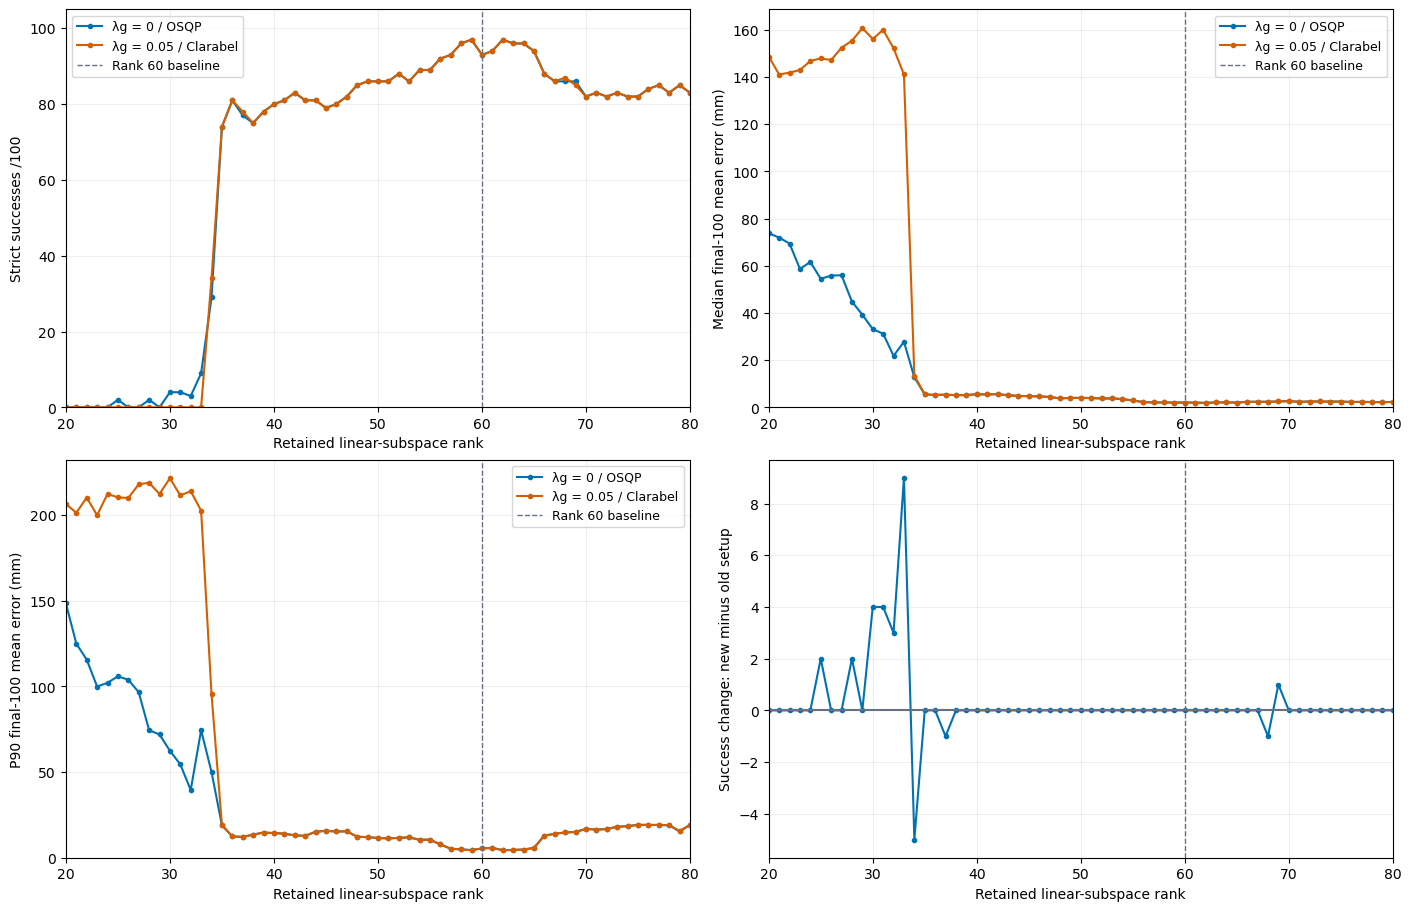

,success_lamg0,success_lamg005,median_mm_lamg0,median_mm_lamg005,p90_mm_lamg0,p90_mm_lamg005,unsolved_lamg0,unsolved_lamg005,net_success_change,repaired_seeds,regressed_seeds
rank,,,,,,,,,,,
20,0,0,73.839,148.714,148.396,206.412,14229,6822,0,[],[]
21,0,0,71.963,141.086,124.948,201.287,14155,6697,0,[],[]
22,0,0,69.445,141.887,115.603,210.199,14266,6498,0,[],[]
23,0,0,58.682,142.996,99.902,199.841,13756,5950,0,[],[]
24,0,0,61.629,146.828,102.057,212.309,13822,5893,0,[],[]
25,2,0,54.481,147.905,105.880,210.273,13663,5180,2,"[221, 290]",[]
26,0,0,55.867,147.230,103.832,209.916,13517,5010,0,[],[]
27,0,0,55.991,152.454,96.587,217.934,13403,4548,0,[],[]
28,2,0,44.828,155.385,74.413,218.781,12833,3278,2,"[222, 247]",[]


Verified paired comparison: 6,100 matching rank/seed/target cases; lambda_g and solver changed.


In [6]:
OLD_ROOT = ROOT / "experiments/routed_deepc_iid/linear_subspace_rank_100_v1"
old_payload = json.loads((OLD_ROOT / "summary.json").read_text())
assert old_payload["complete"] and old_payload["ranks"] == RANKS and old_payload["seeds"] == SEEDS
old_signature = old_payload["signature"]
new_signature = payload["signature"]
assert old_signature["data_sha256"] == new_signature["data_sha256"]
assert old_signature["atlas_sha256"] == new_signature["atlas_sha256"]
config_changes = {key: [value, new_signature["base_config"][key]]
    for key, value in old_signature["base_config"].items()
    if value != new_signature["base_config"][key]}
assert config_changes == {"lam_g": [.05, 0.0]}
for name, digest in old_signature["source_sha256"].items():
    assert experiment.file_digest(OLD_ROOT / "frozen_protocol/src" / name) == digest
assert "cp.CLARABEL," in (OLD_ROOT / "frozen_protocol/src/routed_deepc_experiment.py").read_text()
comparison_rows = []
new_rows = frame.set_index(["rank", "seed"])
for rank in RANKS:
    old_panel = json.loads((OLD_ROOT / f"rank{rank:03d}" / "summary.json").read_text())
    assert old_panel["seeds"] == SEEDS and [r["seed"] for r in old_panel["results"]] == SEEDS
    repaired, regressed = [], []
    for old_row in old_panel["results"]:
        seed = old_row["seed"]
        expected = {**old_signature["base_config"], "seed": seed, "svd_rank": rank}
        assert all(old_row[key] == value for key, value in expected.items())
        new_row = new_rows.loc[(rank, seed)]
        assert new_row.lam_g == 0.0 and new_row.qp_solver == "OSQP"
        np.testing.assert_array_equal(new_row.exact_target_xy, old_row["exact_target_xy"])
        old_success = experiment.strict_success(old_row)
        if new_row.strict and not old_success: repaired.append(seed)
        if old_success and not new_row.strict: regressed.append(seed)
    comparison_rows.append({"rank": rank, "success_lamg0": int(summary.loc[rank, "successes"]),
        "success_lamg005": old_panel["successes"],
        "median_mm_lamg0": float(summary.loc[rank, "median_tail100_mm"]),
        "median_mm_lamg005": old_panel["median_tail100_mm"],
        "p90_mm_lamg0": float(summary.loc[rank, "p90_tail100_mm"]),
        "p90_mm_lamg005": old_panel["p90_tail100_mm"],
        "unsolved_lamg0": int(summary.loc[rank, "unsolved_qps"]),
        "unsolved_lamg005": old_panel["unsolved_qps"],
        "net_success_change": len(repaired)-len(regressed),
        "repaired_seeds": repaired, "regressed_seeds": regressed})
comparison = pd.DataFrame(comparison_rows).set_index("rank")
highlights = sorted({40, 50, 56, 59, 60, 62, 64, 80, *best_ranks})
display(comparison.loc[highlights, ["success_lamg0", "success_lamg005", "median_mm_lamg0", "median_mm_lamg005", "net_success_change"]].round(3))
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for ax, prefix, label in zip(axes.flat[:3], ["success", "median_mm", "p90_mm"],
        ["Strict successes /100", "Median final-100 mean error (mm)", "P90 final-100 mean error (mm)"]):
    for suffix, color, legend in [("lamg0", BLUE, "λg = 0 / OSQP"), ("lamg005", ORANGE, "λg = 0.05 / Clarabel")]:
        ax.plot(RANKS, comparison[f"{prefix}_{suffix}"], color=color, marker=".", label=legend)
    rank_axis(ax, label)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9)
axes.flat[0].set_ylim(0, 105)
axes.flat[3].plot(RANKS, comparison.net_success_change, color=BLUE, marker=".")
axes.flat[3].axhline(0, color=GRAY)
rank_axis(axes.flat[3], "Success change: new minus old setup")
save_show(fig, "rank_setup_comparison.png")
display(HTML("<details><summary>All 61 paired setup comparisons and seed lists</summary>" + comparison.round(3).to_html() + "</details>"))
experiment.write_json(RESULT_ROOT / "setup_comparison_report.json", {
    "complete": True, "paired_rollouts": 6100, "configuration_differences": config_changes, "solver_change": ["CLARABEL", "OSQP"],
    "ranks": comparison.reset_index().to_dict(orient="records")})
print("Verified paired comparison: 6,100 matching rank/seed/target cases; lambda_g and solver changed.")


## Interpretation and reproduction

The success curve tests sensitivity to retained behavioral rank with all other
baseline choices fixed. A larger basis admits more behavioral directions but need
not improve closed-loop stabilization under the same regularization and coefficient
bounds. This study does not isolate those mechanisms or tune their weights.

Differences across adjacent ranks are descriptive on these reused 100 seeds. Any
rank selected from this sweep requires a separate evaluation before claiming a
generalization improvement over rank 60. Timing differences may also reflect system
load and the fixed run order.

When a rank has unsolved QPs, its closed-loop results include the baseline's
zero-input failure handling. Inspect the QP-failure panel alongside success and
error, rather than interpreting every failure to stabilize as the performance of
a successfully solved controller. Unsolved-step counts alone do not establish
mathematical infeasibility or identify a numerical failure mechanism.

To resume this exact launch protocol, run
`python src/linear_subspace_rank_lamg0_osqp_ablation.py --workers 6`
from the project root in the existing `gym-robotics-mujoco` environment. The frozen
runner resumes validated compact checkpoints and retains all original hash checks.
Its data and experiment-directory links reuse the existing files without copying
datasets. Frozen sources protect this repeat from later workspace edits.
The notebook defaults to `RUN_EXPERIMENTS=False` and refuses to present a partial
sweep as complete. The archived contextual affine study remains at
`archive/notebooks/ablation_affine_rank_contextual.ipynb`.
